<a href="https://colab.research.google.com/github/3b232106/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 作業3 - 四資四乙 3B232106 陳威廷

## a. 資料預處理

In [71]:
from tensorflow.keras import utils   # tf 2.0
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(10)

In [72]:
from keras.datasets import fashion_mnist
(x_train_image,y_train_label),\
(x_test_image,y_test_label)= fashion_mnist.load_data()

In [73]:
x_Train = x_train_image.reshape(60000, 784).astype('float32')
x_Test = x_test_image.reshape(10000, 784).astype('float32')

In [74]:
x_Train_normalize = x_Train / 255
x_Test_normalize = x_Test / 255

In [75]:
y_Train_OneHot = utils.to_categorical(y_train_label)
y_Test_OneHot = utils.to_categorical(y_test_label)

In [76]:
# 資料類別標籤
labels_name = ["T-shirt/top(T恤)","Trouser(褲子)","Pullover(套衫)","Dress(裙子)","Coat(外套)","Sandal(涼鞋)","Shirt(汗衫)","Sneaker(運動鞋)","Bag(包)","Ankle boot(踝靴)"]

/tmp/ipykernel_1555/2572458697.py:8: UserWarning: Glyph 36381 (\N{CJK UNIFIED IDEOGRAPH-8E1D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1555/2572458697.py:8: UserWarning: Glyph 38772 (\N{CJK UNIFIED IDEOGRAPH-9774}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1555/2572458697.py:8: UserWarning: Glyph 24676 (\N{CJK UNIFIED IDEOGRAPH-6064}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


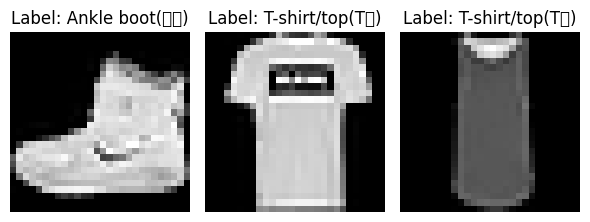

In [77]:
# 呈現訓練資料、測試資料的形狀
plt.figure(figsize=(6, 3))
for i in range(0, 3):
  plt.subplot(1, 3, i + 1)
  plt.imshow(x_train_image[i], cmap='gray')
  plt.title(f"Label: {labels_name[y_train_label[i]]}")
  plt.axis("off")
plt.tight_layout()
plt.show()

## b. 建立神經網路模型

In [78]:
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout

In [79]:
model = Sequential()

In [80]:
# 輸入層
model.add(Dense(units=256,
        input_dim=784,
        kernel_initializer='normal',
        activation='relu'))
# 隱藏層1
model.add(Dropout(0.1))

In [81]:
# 隱藏層2
model.add(Dense(units=10,
        kernel_initializer='normal',
        activation='relu'))
model.add(Dropout(0.5))

In [82]:
# 輸出層
model.add(Dense(units=10,
        kernel_initializer='normal',
        activation='softmax'))

In [83]:
print(model.summary())

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         2,570 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,640 (795.47 KB)

 Trainable params: 203,640 (795.47 KB)

 Non-trainable params: 0 (0.00 B)

None


### 根據上面那張表模型架構與參數數量說明

* **hidden_layer_1 (Dense)**[cite: 4]
  * **計算方式**：$(\text{輸入維度} \times \text{神經元數}) + \text{偏置 (Bias)}$
  * **參數計算**：$784 \times 256 + 256 = \mathbf{200,960}$[cite: 3, 4]

* **dropout_7 (Dropout)**[cite: 4]
  * **參數計算**：不包含可訓練參數 = $\mathbf{0}$[cite: 4]

* **hidden_layer_2 (Dense)**[cite: 3, 4]
  * **計算方式**：$(\text{上一層輸出維度} \times \text{神經元數}) + \text{偏置 (Bias)}$
  * **參數計算**：$256 \times 10 + 10 = \mathbf{2,570}$[cite: 3, 4]

* **dropout_8 (Dropout)**[cite: 4]
  * **參數計算**：不包含可訓練參數 = $\mathbf{0}$[cite: 4]

* **output_layer (Dense)**[cite: 3, 4]
  * **計算方式**：$(\text{上一層輸出維度} \times \text{神經元數}) + \text{偏置 (Bias)}$
  * **參數計算**：$10 \times 10 + 10 = \mathbf{110}$[cite: 3, 4]

* **總參數數量**：$200,960 + 0 + 2,570 + 0 + 110 = \mathbf{203,640}$ 個參數[cite: 4]

## c. 訓練神經網路模型


In [84]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

## 驗證(validation)用資料
* 從訓練資料當中切出20%作為**驗證(validation)**用資料
* 全部訓練資料60000筆資料(手寫數字圖片)當中，12000筆當作驗證資料，故真正訓練資料只剩48000筆

## 批次大小(batch_size)


In [85]:
train_history =model.fit(x=x_Train_normalize,
             y=y_Train_OneHot,validation_split=0.2,
             epochs=30, batch_size=200, verbose=2)

Epoch 1/30
240/240 - 11s - 44ms/step - accuracy: 0.4333 - loss: 1.4175 - val_accuracy: 0.7534 - val_loss: 0.7858
Epoch 2/30
240/240 - 5s - 22ms/step - accuracy: 0.5553 - loss: 1.1149 - val_accuracy: 0.7772 - val_loss: 0.6700
Epoch 3/30
240/240 - 7s - 30ms/step - accuracy: 0.5859 - loss: 1.0466 - val_accuracy: 0.7749 - val_loss: 0.6424
Epoch 4/30
240/240 - 3s - 11ms/step - accuracy: 0.5978 - loss: 1.0110 - val_accuracy: 0.8123 - val_loss: 0.5991
Epoch 5/30
240/240 - 2s - 9ms/step - accuracy: 0.6134 - loss: 0.9799 - val_accuracy: 0.8372 - val_loss: 0.5659
Epoch 6/30
240/240 - 3s - 13ms/step - accuracy: 0.6159 - loss: 0.9601 - val_accuracy: 0.8411 - val_loss: 0.5595
Epoch 7/30
240/240 - 3s - 14ms/step - accuracy: 0.6343 - loss: 0.9334 - val_accuracy: 0.8417 - val_loss: 0.5377
Epoch 8/30
240/240 - 2s - 9ms/step - accuracy: 0.6425 - loss: 0.9164 - val_accuracy: 0.8453 - val_loss: 0.5253
Epoch 9/30
240/240 - 2s - 10ms/step - accuracy: 0.6453 - loss: 0.9037 - val_accuracy: 0.8347 - val_loss: 

## d. 以折線圖顯示訓練過程的 loss & accuracy
* 每一epoch訓練後，計算神經網路所有批次的平均準確率(accuracy)與平均損失(loss)。
* 每一epoch訓練後，用驗證資料驗證神經網路的準確率(val_accuracy)與損失(val_loss)。

In [86]:
import matplotlib.pyplot as plt

# 畫出訓練過程每一個epoch訓練資料與驗證資料各自準確率(accuracy)的變化，或者損失誤差(loss)的變化
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

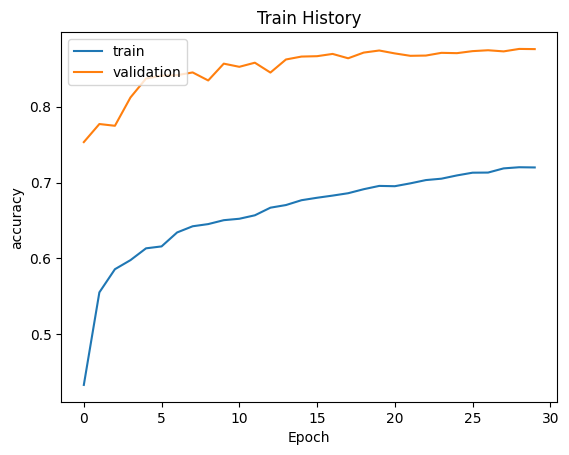

In [87]:
# 準確率(accuracy)
show_train_history(train_history,'accuracy','val_accuracy')

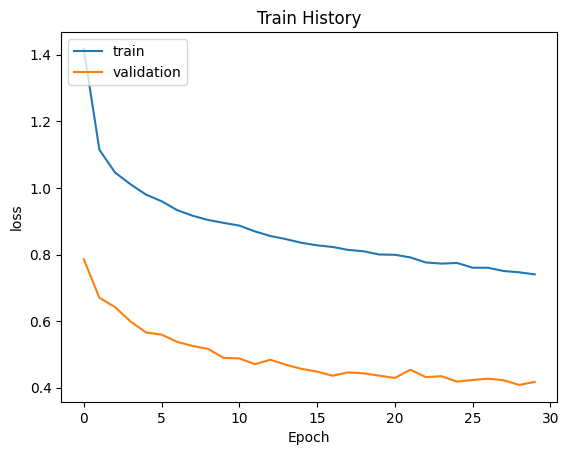

In [88]:
# 損失誤差(loss)
show_train_history(train_history,'loss','val_loss')

## e. 評估模型準確率

In [89]:
scores = model.evaluate(x_Test_normalize, y_Test_OneHot)
print()
print('accuracy=',scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8699 - loss: 0.4381

accuracy= 0.8698999881744385


## f. 進行預測

In [90]:
# 用全部測試資料，必須呈現數張測試資料(圖片)、測試資料預測的結果(標籤名稱)、與測試資料真實的標籤名稱
def plot_images_labels_prediction(images,labels,prediction,idx,num=10):
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    if num>25: num=25
    for i in range(0, num):
        ax=plt.subplot(5,5, 1+i)
        ax.imshow(images[idx], cmap='binary')
        title= "label=" +str(labels_name[labels[idx]])+"\n"
        if len(prediction)>0:
            title+="predict="+str(labels_name[np.argmax(prediction[idx])])

        ax.set_title(title,fontsize=10)
        ax.set_xticks([]);ax.set_yticks([])
        idx+=1
    plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22871 (\N{CJK UNIFIED IDEOGRAPH-5957}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 34923 (\N{CJK UNIFIED IDEOGRAPH-886B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22806 (\N{CJK UNIFIED IDEOGRAPH-5916}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35122 (\N{CJK UNIFIED IDEOGRAPH-8932}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  fig.canvas

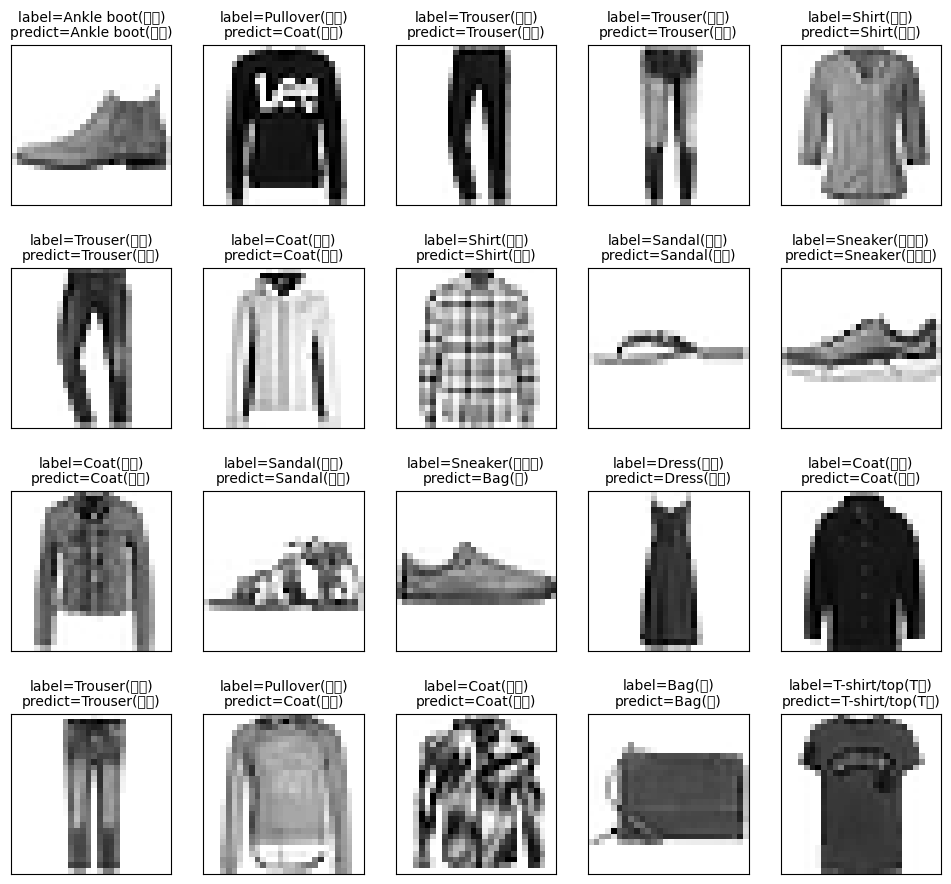

In [91]:
prediction = model.predict(x_Test)
plot_images_labels_prediction(x_test_image,y_test_label,
               prediction,idx=0,num=20)

## g. 以混淆矩陣(Confusion matrix)呈現預測結果
*   預測結果與真實結果相同或不同的情形

In [92]:
import pandas as pd
# 將10000個預測結果一一轉換為
predicted_labels = np.argmax(prediction, axis=1)

# Now use predicted_labels in crosstab
pd.crosstab(y_test_label, predicted_labels, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,886,1,2,11,18,0,61,0,21,0
1,1,975,1,17,3,0,1,0,2,0
2,10,1,349,6,582,0,47,0,5,0
3,41,18,2,839,64,0,25,0,8,3
4,0,0,13,17,949,0,17,0,4,0
5,0,0,0,1,0,859,0,8,6,126
6,252,2,20,14,286,0,400,0,26,0
7,0,0,0,0,0,9,0,716,1,274
8,0,0,0,3,8,1,1,2,982,3


In [93]:
# 每一筆測試資料的真實結果標籤(label)與預測結果標籤(predict)的表格(df)
df = pd.DataFrame({'label': y_test_label, 'predict': predicted_labels})
df[:10] # 表格前10筆測試資料

,label,predict
0,9,9
1,2,4
2,1,1
3,1,1
4,6,6
5,1,1
6,4,4
7,6,6
8,5,5
9,7,7


##　h. 儲存完整模型

In [94]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

%cd '/content/drive/My Drive/Colab Notebooks'

model.save('hw3.keras')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/Colab Notebooks
